In [67]:
import pandas as pd

df = pd.read_csv('../data/sales_history.csv')

df.isna().sum()

df_test = df.copy()

In [68]:
df_test.fillna(0, inplace=True)

df_ordenat = df_test.sort_values(by=['channel','product_line', 'region', 'month'], ascending=True)
conteo = df_ordenat.groupby(['channel','product_line', 'region'])['month'].size().reset_index(name='counts')
df_ordenat = df_ordenat.sort_values(["channel", "product_line", "region", "month"]).copy()

grup = df_ordenat.groupby(["channel", "product_line", "region"])["sales_units"]

train = df_ordenat[df_ordenat["month"].between("2022-01", "2024-12")].copy()
val = df_ordenat[df_ordenat["month"].between("2025-01", "2025-12")].copy()
test = df_ordenat[df_ordenat["month"].between("2026-01", "2026-06")].copy()

for nombre, datos in [("Entrenamiento", train), ("Validación", val), ("Prueba", test)]:
    print(nombre, len(datos), datos["month"].min(), datos["month"].max())

grupo_media = (train.groupby(["channel", "product_line", "region"])["sales_units"].mean().rename("pred_media").reset_index())

claves = ["channel", "product_line", "region"]

# Añadimos a cada mes las ventas de esa serie 12 meses antes.
df_con_lag = df_ordenat.copy()
df_con_lag["pred_año_anterior"] = (df_con_lag.groupby(claves)["sales_units"].shift(12))

# Nos quedamos con los meses de validación: 2025.
val_comparar = df_con_lag[df_con_lag["month"].between("2025-01", "2025-12")].copy()

# A cada fila le añadimos la media de entrenamiento de su grupo.
comparacion = val_comparar.merge(grupo_media,on=claves,how="left")

comparacion[["month", *claves, "sales_units", "pred_media", "pred_año_anterior"]].head(12)

Entrenamiento 648 2022-01 2024-12
Validación 216 2025-01 2025-12
Prueba 108 2026-01 2026-06


,month,channel,product_line,region,sales_units,pred_media,pred_año_anterior
0,2025-01,ecommerce,electric,coast,60,70.222222,55.0
1,2025-02,ecommerce,electric,coast,76,70.222222,75.0
2,2025-03,ecommerce,electric,coast,57,70.222222,82.0
3,2025-04,ecommerce,electric,coast,121,70.222222,118.0
4,2025-05,ecommerce,electric,coast,83,70.222222,90.0
5,2025-06,ecommerce,electric,coast,109,70.222222,68.0
6,2025-07,ecommerce,electric,coast,102,70.222222,92.0
7,2025-08,ecommerce,electric,coast,104,70.222222,72.0
8,2025-09,ecommerce,electric,coast,81,70.222222,79.0
9,2025-10,ecommerce,electric,coast,76,70.222222,59.0


In [69]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

train["month"] = pd.to_datetime(train["month"], format="%Y-%m")
train["year"] = train["month"].dt.year
train["month_num"] = train["month"].dt.month
train = train.drop(columns=["month"])

val["month"] = pd.to_datetime(val["month"], format="%Y-%m")
val["year"] = val["month"].dt.year
val["month_num"] = val["month"].dt.month
val = val.drop(columns=["month"])

columnas_a_quitar = [
    "sales_units",
    "closing_stock_units",
    "revenue",
    "stockout",
    "website_sessions",
    "marketing_spend",
    "avg_discount",
]

X = train.drop(columns=columnas_a_quitar)
y = train["sales_units"]

X_2025 = val.drop(columns=columnas_a_quitar)
y_2025 = val["sales_units"]

X = pd.get_dummies(X, drop_first=False, dtype=int)
X_2025 = pd.get_dummies(X_2025, drop_first=False, dtype=int)
X_2025 = X_2025.reindex(columns=X.columns, fill_value=0)

model = LinearRegression()
model.fit(X, y)

prediccion = model.predict(X_2025)


# 1. Regresio Lineal


In [70]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_lineal = LinearRegression()
model_lineal.fit(X, y)

prediccion = model_lineal.predict(X_2025)

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", prediccion[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccion))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccion)))
print("R²:", r2_score(y_2025, prediccion))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [ 70.95  78.81  57.32 102.45  87.49  85.82  98.73  86.22  82.92  64.23
  77.01  75.59]
MAE: 13.619895808136313
RMSE: 18.308653410662686
R²: 0.8471975837702336


# 2. Decision Tree Regressor

In [71]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error

model_Decision_Tree = DecisionTreeRegressor(random_state=1)
model_Decision_Tree.fit(X, y)

prediccio_Tree = model_Decision_Tree.predict(X_2025)
print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", prediccio_Tree[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccio_Tree))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_Tree)))
print("R²:", r2_score(y_2025, prediccio_Tree))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [ 47. 106.  54.  82.  82.  82.  93.  96. 106.  84.  58.  91.]
MAE: 21.13425925925926
RMSE: 27.64331343702809
R²: 0.6516646010853994


# 3. SVR

In [72]:
from sklearn.svm import SVR

model_svr = SVR()
model_svr.fit(X, y)
prediccio_svr = model_svr.predict(X_2025)
print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", prediccio_svr[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccio_svr))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_svr)))
print("R²:", r2_score(y_2025, prediccio_svr))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [76.7  77.89 79.46 79.25 78.08 75.72 76.16 77.85 76.26 73.9  75.35 73.78]
MAE: 32.7957120771287
RMSE: 43.95782114083628
R²: 0.11917480210197184


# 4. Random Forest Regresor

In [73]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(random_state=1)
model_rf.fit(X, y)
prediccio_rf = model_rf.predict(X_2025)
print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", prediccio_rf[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccio_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_rf)))
print("R²:", r2_score(y_2025, prediccio_rf))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [ 68.09  80.41  47.17 102.33  88.28  89.76 109.02  89.5   80.12  58.92
  62.43  77.9 ]
MAE: 14.95736111111111
RMSE: 20.407089329627766
R²: 0.8101635752851222


# 5. Gradient Boosting Regressor

In [74]:
from sklearn.ensemble import GradientBoostingRegressor

model_gb = GradientBoostingRegressor(random_state=1)
model_gb.fit(X, y)
preds_gb = model_gb.predict(X_2025)
print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", preds_gb[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, preds_gb))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, preds_gb)))
print("R²:", r2_score(y_2025, preds_gb))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [ 72.72  78.22  55.57  90.6   84.15  83.14 106.36  86.81  82.79  55.83
  68.9   75.21]
MAE: 14.3386412590856
RMSE: 19.713870916157013
R²: 0.8228418110514023


# 6. Ridge
És una regressió lineal que frena els coeficients massa grans per evitar el sobreajust.

> **Opinió / Conclusió:** En un cas tan bàsic com este és una mica tonteria complicar-se: la regressió lineal simple funciona pràcticament igual o millor sense tocar cap paràmetre.

In [75]:
from sklearn.linear_model import Ridge

model_ridge = Ridge()
model_ridge.fit(X, y)
prediccio_ridge = model_ridge.predict(X_2025)

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", prediccio_ridge[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccio_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_ridge)))
print("R²:", r2_score(y_2025, prediccio_ridge))


Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [72.97 75.22 55.97 97.96 84.47 82.77 94.72 84.23 75.73 62.81 68.44 71.6 ]
MAE: 14.27199306069278
RMSE: 18.634072993384052
R²: 0.8417174641002837


# 7. Lasso
Intenta netejar variables posant a zero les que menys aporten.

> **Opinió / Conclusió:** Com que ací tenim poques columnes i quasi totes aporten informació útil, és una tonteria forçar-lo a apagar variables perquè només aconseguim empitjorar l'error.

In [76]:
from sklearn.linear_model import Lasso

model_lasso = Lasso()
model_lasso.fit(X, y)
prediccio_lasso = model_lasso.predict(X_2025)

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", prediccio_lasso[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccio_lasso))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_lasso)))
print("R²:", r2_score(y_2025, prediccio_lasso))


Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [ 73.64  78.95  50.86  95.42  87.2   86.92 100.51  88.19  76.9   61.75
  64.03  72.56]
MAE: 14.81121020013027
RMSE: 19.504947301216177
R²: 0.8265768871062535


# 8. KNN (K-Neighbors Regressor)
Prediu buscant els mesos més pareguts del passat basant-se en distàncies.

> **Opinió / Conclusió:** És una tonteria gastar-lo ací. Com que tenim moltes columnes categòriques i dades sense escalar, el càlcul de distàncies es perd i trau un error molt roín (MAE 23.12).

In [77]:
from sklearn.neighbors import KNeighborsRegressor

model_knn = KNeighborsRegressor()
model_knn.fit(X, y)
prediccio_knn = model_knn.predict(X_2025)

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", prediccio_knn[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccio_knn))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_knn)))
print("R²:", r2_score(y_2025, prediccio_knn))


Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [69.4 71.4 66.8 80.6 72.4 78.6 73.8 60.6 77.2 47.4 71.4 55.4]
MAE: 23.116666666666667
RMSE: 31.36626519993403
R²: 0.5515200468726453


# 9. AdaBoost Regressor
Combina arbrets petits de forma seqüencial per intentar millorar la precisió.

> **Opinió / Conclusió:** Massa complexitat per a no res. Per a unes dades tan lineals com estes, embolicar-se amb un model de boosting no aporta cap avantatge i només fa més lent el codi.

In [78]:
from sklearn.ensemble import AdaBoostRegressor

model_ada = AdaBoostRegressor(random_state=1)
model_ada.fit(X, y)
prediccio_ada = model_ada.predict(X_2025)

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", prediccio_ada[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccio_ada))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_ada)))
print("R²:", r2_score(y_2025, prediccio_ada))


Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [ 76.15  79.08  48.46  91.35  87.36  88.19 102.2   88.19  79.43  71.4
  63.52  76.43]
MAE: 15.17828421090338
RMSE: 19.98714834376968
R²: 0.8178961672672745


# 10. Bagging Regressor
Entrena múltiples còpies del model amb mostres aleatòries per reduir la variància.

> **Opinió / Conclusió:** Una altra tonteria per a este problema: no cal fer un "comitè" d'arbres quan una senzilla recta de regressió lineal ja resol el patró principal a la primera.

In [79]:
from sklearn.ensemble import BaggingRegressor

model_bagging = BaggingRegressor(random_state=1)
model_bagging.fit(X, y)
prediccio_bagging = model_bagging.predict(X_2025)

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones: ", prediccio_bagging[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccio_bagging))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_bagging)))
print("R²:", r2_score(y_2025, prediccio_bagging))


Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones:  [ 68.5  78.8  53.4 101.6  92.   93.8 111.8  92.8  80.3  56.9  67.4  83.5]
MAE: 15.987037037037036
RMSE: 21.77553418148195
R²: 0.783850094451882


# 11. Isotonic regression

In [80]:
from sklearn.isotonic import IsotonicRegression

model_isotonic = IsotonicRegression(out_of_bounds="clip")
model_isotonic.fit(X["month_num"], y)
prediccio_isotonic = model_isotonic.predict(X_2025["month_num"])

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones:", prediccio_isotonic[:12].round(2))

print("MAE:", mean_absolute_error(y_2025, prediccio_isotonic))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_isotonic)))
print("R²:", r2_score(y_2025, prediccio_isotonic))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones: [ 75.33  86.2   96.43 102.74 102.74 102.74 102.74 102.74 102.74 102.74
 102.74 102.74]
MAE: 35.8741426611797
RMSE: 45.95457651228451
R²: 0.03733551167741256


# 12. Kernel Ridge Regression
Modelo de regresión con kernel para capturar relaciones no lineales.

In [81]:
from sklearn.kernel_ridge import KernelRidge

model_kernel_ridge = KernelRidge()
model_kernel_ridge.fit(X, y)
prediccio_kernel_ridge = model_kernel_ridge.predict(X_2025)

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones:", prediccio_kernel_ridge[:12].round(2))
print("MAE:", mean_absolute_error(y_2025, prediccio_kernel_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_kernel_ridge)))
print("R²:", r2_score(y_2025, prediccio_kernel_ridge))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones: [75.   77.29 58.21 99.87 86.31 84.66 96.42 86.04 77.68 64.89 70.48 73.53]
MAE: 13.96977808519646
RMSE: 18.359237984806818
R²: 0.8463520685118235


# 13. Stochastic Gradient Descent Regressor
Regresión entrenada mediante descenso de gradiente estocástico.

In [82]:
from sklearn.linear_model import SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_sgd = make_pipeline(StandardScaler(), SGDRegressor(random_state=1))
model_sgd.fit(X, y)
prediccio_sgd = model_sgd.predict(X_2025)

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones:", prediccio_sgd[:12].round(2))
print("MAE:", mean_absolute_error(y_2025, prediccio_sgd))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_sgd)))
print("R²:", r2_score(y_2025, prediccio_sgd))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones: [68.3  75.61 54.61 99.14 83.93 81.98 94.6  82.25 78.59 60.11 72.57 71.1 ]
MAE: 14.124375344529353
RMSE: 18.56023392101452
R²: 0.8429693943043575


# 14. Gaussian Process Regressor
Regresión basada en procesos gaussianos para estimar las ventas.

In [83]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model_gaussian_process = make_pipeline(
    StandardScaler(),
    GaussianProcessRegressor(normalize_y=True)
)
model_gaussian_process.fit(X, y)
prediccio_gaussian_process = model_gaussian_process.predict(X_2025)

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones:", prediccio_gaussian_process[:12].round(2))
print("MAE:", mean_absolute_error(y_2025, prediccio_gaussian_process))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_gaussian_process)))
print("R²:", r2_score(y_2025, prediccio_gaussian_process))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones: [ 94.52  88.52  85.74 121.15  97.39  90.84  95.66  77.17  64.12  74.85
  90.81  68.07]
MAE: 20.32367629985622
RMSE: 26.739646438244435
R²: 0.6740666983441063


# 15. Partial Least Squares Regression
Regresión por mínimos cuadrados parciales, del grupo de descomposición cruzada.

In [84]:
from sklearn.cross_decomposition import PLSRegression

model_pls = PLSRegression(n_components=2)
model_pls.fit(X, y)
prediccio_pls = model_pls.predict(X_2025).ravel()

print("Ventas reales:", y_2025.to_numpy()[:12])
print("Predicciones:", prediccio_pls[:12].round(2))
print("MAE:", mean_absolute_error(y_2025, prediccio_pls))
print("RMSE:", np.sqrt(mean_squared_error(y_2025, prediccio_pls)))
print("R²:", r2_score(y_2025, prediccio_pls))

Ventas reales: [ 60  76  57 121  83 109 102 104  81  76  68  68]
Predicciones: [ 72.05  74.84  64.08 103.34  81.07  79.1   87.03  79.7   76.99  66.12
  78.56  75.95]
MAE: 15.043556404037965
RMSE: 19.409915224839512
R²: 0.8282626757884604


# 16. Comparativa de todos los modelos

Comparamos todos los regresores sobre la misma validación de 2025 mediante MAE, RMSE y R².

In [85]:
models_dict = {
    "LinearRegression": prediccion,
    "DecisionTree": prediccio_Tree,
    "SVR": prediccio_svr,
    "RandomForest": prediccio_rf,
    "GradientBoosting": preds_gb,
    "Ridge": prediccio_ridge,
    "Lasso": prediccio_lasso,
    "KNN": prediccio_knn,
    "AdaBoost": prediccio_ada,
    "Bagging": prediccio_bagging,
    "IsotonicRegression": prediccio_isotonic,
    "KernelRidge": prediccio_kernel_ridge,
    "SGDRegressor": prediccio_sgd,
    "GaussianProcessRegressor": prediccio_gaussian_process,
    "PLSRegression": prediccio_pls
}

resum = []
for nom, pred in models_dict.items():
    resum.append({
        "Model": nom,
        "MAE": round(mean_absolute_error(y_2025, pred), 2),
        "RMSE": round(np.sqrt(mean_squared_error(y_2025, pred)), 2),
        "R²": round(r2_score(y_2025, pred), 4)
    })

df_resum = pd.DataFrame(resum).sort_values("MAE").reset_index(drop=True)
df_resum

,Model,MAE,RMSE,R²
0,LinearRegression,13.62,18.31,0.8472
1,KernelRidge,13.97,18.36,0.8464
2,SGDRegressor,14.12,18.56,0.8430
3,Ridge,14.27,18.63,0.8417
4,GradientBoosting,14.34,19.71,0.8228
5,Lasso,14.81,19.50,0.8266
6,RandomForest,14.96,20.41,0.8102
7,PLSRegression,15.04,19.41,0.8283
8,AdaBoost,15.18,19.99,0.8179
9,Bagging,15.99,21.78,0.7839


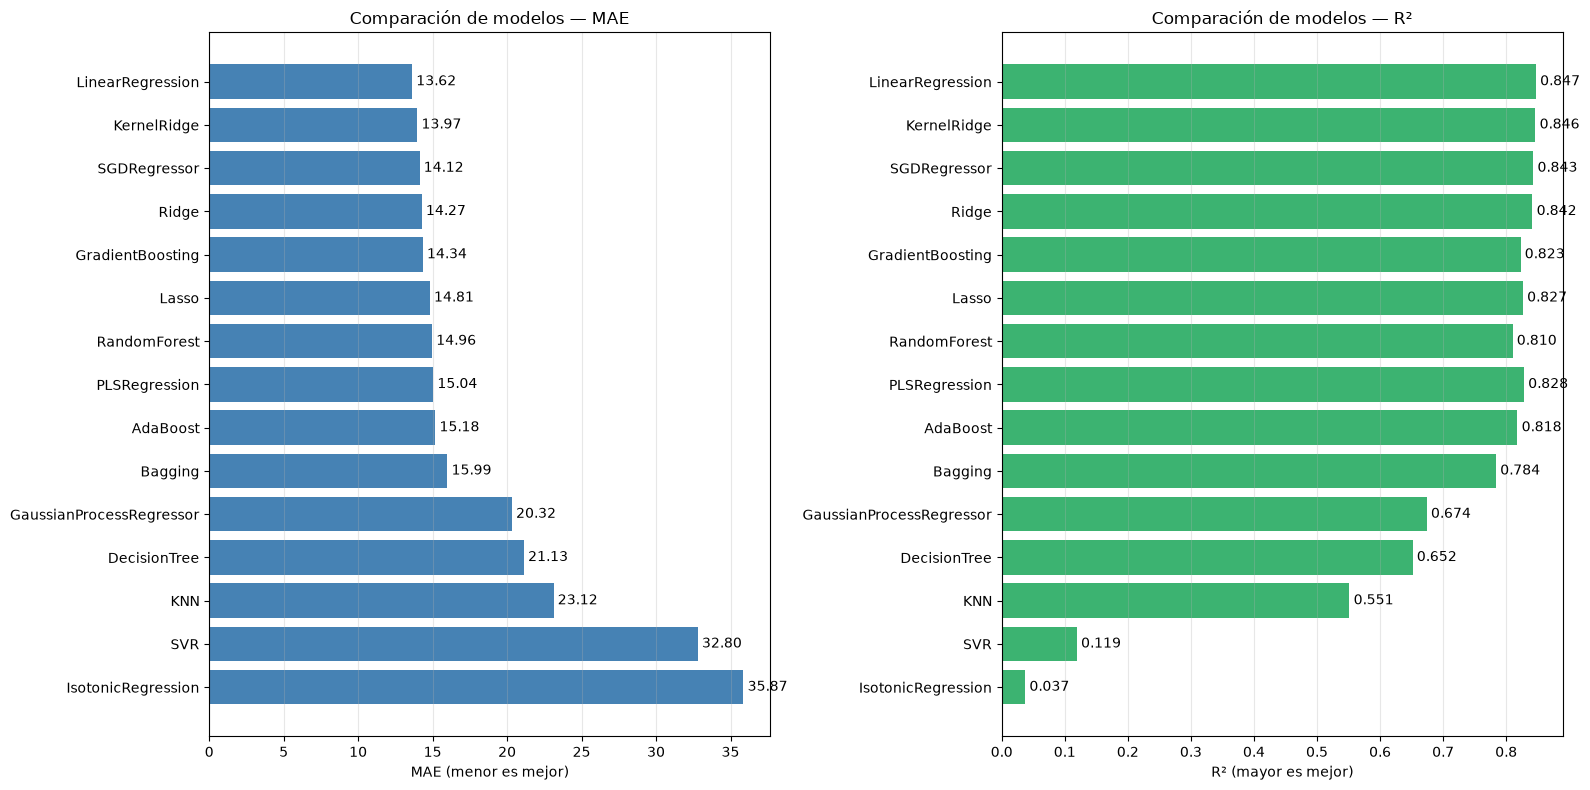

In [86]:
import matplotlib.pyplot as plt

grafico = df_resum.sort_values("MAE", ascending=True)
fig, (ax_mae, ax_r2) = plt.subplots(1, 2, figsize=(16, 8))

ax_mae.barh(grafico["Model"], grafico["MAE"], color="steelblue")
ax_mae.invert_yaxis()
ax_mae.set_title("Comparación de modelos — MAE")
ax_mae.set_xlabel("MAE (menor es mejor)")
ax_mae.grid(axis="x", alpha=0.3)
ax_mae.bar_label(ax_mae.containers[0], fmt="%.2f", padding=3)

ax_r2.barh(grafico["Model"], grafico["R²"], color="mediumseagreen")
ax_r2.invert_yaxis()
ax_r2.set_title("Comparación de modelos — R²")
ax_r2.set_xlabel("R² (mayor es mejor)")
ax_r2.grid(axis="x", alpha=0.3)
ax_r2.bar_label(ax_r2.containers[0], fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()